# Sesión 12 · Resumir datos con tablas de frecuencia
**Introducción a la Ingeniería en Ciencia de Datos — Universidad del Magdalena · período 2026-3C**

Ing. Alexander Bustamante Martínez MSc. PhD. · Ing. Andrés Eduardo Paternina Ariza Esp.

Notebook de acompañamiento de las diapositivas de la Sesión 12. Sigue su mismo orden: los datos del curso, la clasificación
de variables, las tablas de datos simples (P1, P2, P5), los gráficos, las tablas por intervalos (P3, P4) y las tablas cruzadas
(P6, P7, P8). Cada diapositiva con código tiene aquí su celda ejecutable.

Archivo de datos: `datos_curso_2026_2.csv` (la hoja de recolección del curso, n = 18).

## 1. Los datos del curso
*Dieciocho estudiantes, nueve variables, ocho preguntas.*

> **¿Qué sabemos de nosotros mismos como curso?** ¿Cuántos somos de cada edad, cómo llegamos a la universidad, cuánto sabemos
> de Python? Las ocho preguntas de la *Actividad de cálculo de frecuencias* son la guía de estas dos sesiones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 40)
curso = pd.read_csv("datos_curso_2026_2.csv")
curso                      # así quedó la hoja de recolección (n = 18)

,estudiante,edad,estatura_m,peso_kg,mano,n_mascotas,transporte,horas_estudio,nivel_python
0,1,17,1.73,61,Derecha,1,A pie,3,Básico
1,2,17,1.76,70,Derecha,3,Bicicleta,2,Básico
2,3,17,1.44,82,Derecha,0,Moto,1,Intermedio
3,4,19,1.58,53,Derecha,3,Moto,4,Básico
4,5,17,1.58,55,Derecha,4,A pie,4,Básico
5,6,17,1.73,55,Derecha,1,Moto,4,Básico
6,7,18,1.75,62,Derecha,0,Auto p.,3,Básico
7,8,18,1.86,62,Derecha,1,Moto,3,Básico
8,9,16,1.76,72,Derecha,0,Moto,2,Básico
9,10,19,1.52,43,Derecha,3,Moto,4,Básico


In [2]:
curso.head()               # un primer vistazo: las primeras 5 filas

,estudiante,edad,estatura_m,peso_kg,mano,n_mascotas,transporte,horas_estudio,nivel_python
0,1,17,1.73,61,Derecha,1,A pie,3,Básico
1,2,17,1.76,70,Derecha,3,Bicicleta,2,Básico
2,3,17,1.44,82,Derecha,0,Moto,1,Intermedio
3,4,19,1.58,53,Derecha,3,Moto,4,Básico
4,5,17,1.58,55,Derecha,4,A pie,4,Básico


In [3]:
curso.shape                # (filas, columnas) = (unidades observadas, variables)

(18, 9)

## 2. Tabla de frecuencias: simple o por intervalos
Una tabla de frecuencias responde **cuántas veces aparece cada valor**. Con 18 filas se puede contar a mano; con 18 000, no.
Por eso aprendemos las dos formas.

| Simple | Por intervalos |
|---|---|
| Cada valor distinto ocupa una fila. Sirve cuando hay **pocos valores**, como la edad. | Los valores se agrupan en rangos. Sirve cuando hay **muchos valores**, como el peso. |

In [4]:
# Simple: una fila por cada edad distinta
curso["edad"].value_counts().sort_index()

edad
16    1
17    9
18    6
19    2
Name: count, dtype: int64

In [5]:
# Por intervalos: el peso tiene 13 valores distintos en 18 estudiantes; se agrupa en rangos de 10 kg
print("Valores distintos de peso:", curso["peso_kg"].nunique())
rangos_peso = pd.cut(curso["peso_kg"], bins=[40, 50, 60, 70, 80, 90], right=False,
                     labels=["40 – 49", "50 – 59", "60 – 69", "70 – 79", "80 – 89"])
rangos_peso.value_counts(sort=False)

Valores distintos de peso: 13


peso_kg
40 – 49    1
50 – 59    3
60 – 69    7
70 – 79    5
80 – 89    2
Name: count, dtype: int64

Las dos tablas suman 18. La diferencia es qué ocupa cada fila: un valor (edad) o un rango de valores (peso). Cómo se
construyen los rangos con rigor se verá en P3.

## 3. Lo que hacemos se llama estadística descriptiva
**Estadística descriptiva:** técnicas para **resumir, organizar y describir** un conjunto de datos sin ir más allá de lo
observado. Responde «¿qué hay aquí?», no «¿qué pasará?».

| Dato | Información | Conocimiento |
|---|---|---|
| Un registro crudo, sin contexto | El dato que ya respondió a una pregunta | Comprensión que habilita una decisión |
| La celda `17` en la fila del estudiante 5 | «La mitad del curso tiene 17 años» | «Los ejemplos se diseñan para estudiantes de 17 a 18 años» |

In [6]:
print("Dato:        ", curso.loc[curso["estudiante"] == 5, "edad"].item())
print("Información: ", (curso["edad"] == 17).sum(), "de", len(curso), "estudiantes tienen 17 años")

Dato:         17
Información:  9 de 18 estudiantes tienen 17 años


## 4. Clasificar las variables
*Parte 2 de la actividad: el tipo decide la tabla y el gráfico.*

### Tres conceptos antes de contar
| Concepto | Definición | En el curso |
|---|---|---|
| **Unidad de observación** | El elemento sobre el que se registran los datos | Un estudiante del curso |
| **Variable estadística** | Característica observable de la unidad que puede tomar distintos valores | edad, mano, transporte… |
| **Tamaño de la muestra (n)** | Número de unidades observadas. Es el total contra el que se calculan proporciones | n = 18 |

In [7]:
n = len(curso)
print("Unidades observadas (filas):", n)
print("Variables (columnas):", list(curso.columns))

Unidades observadas (filas): 18
Variables (columnas): ['estudiante', 'edad', 'estatura_m', 'peso_kg', 'mano', 'n_mascotas', 'transporte', 'horas_estudio', 'nivel_python']


### Escalas de medición y operaciones válidas
| Tipo | Subtipo | ¿Ordenar? | ¿Sumar / promediar? | Ejemplo en el curso | Tabla típica |
|---|---|---|---|---|---|
| Cualitativa | Nominal | No | No | mano, transporte | Simple, sin acumuladas |
| Cualitativa | Ordinal | Sí | No | nivel de Python | Simple, con acumuladas |
| Cuantitativa | Discreta | Sí | Sí | edad, mascotas, horas | Simple o por intervalos |
| Cuantitativa | Continua | Sí | Sí | estatura, peso | Por intervalos |

**Regla:** las frecuencias acumuladas solo tienen sentido cuando los valores tienen orden; agrupar en intervalos, solo en
cuantitativas.

*Fuente: Stevens, S. S. (1946). On the theory of scales of measurement. Science, 103(2684), 677–680.*

### El tipo no está escrito en los datos: dos preguntas lo deciden
1. **¿Tiene sentido sumar dos valores?** No → cualitativa o identificador. El código estudiantil es un número en pandas, pero
   sumar dos códigos no significa nada.
2. **¿Tiene sentido ordenar los valores?** Sí → ordinal o cuantitativa: se puede acumular. El nivel de Python es texto, pero
   Básico < Intermedio.

- **Ordinal:** orden sin distancia medible; son posiciones, no números.
- **Discreta = contar** (edad, mascotas) · **Continua = medir** (estatura, peso).

### Actividad: clasifique las nueve variables
Para cada una: tipo (cualitativa / cuantitativa) · subtipo (nominal, ordinal / discreta, continua) · justificación de una línea.

Código estudiantil · Edad (años) · Estatura (m) · Peso (kg) · Mano con la que escribe · N° de mascotas ·
Transporte a la universidad · Horas de estudio diario · Nivel de dominio de Python

### ¿Qué dice pandas sobre los tipos?

In [8]:
curso.dtypes

estudiante         int64
edad               int64
estatura_m       float64
peso_kg            int64
mano                 str
n_mascotas         int64
transporte           str
horas_estudio      int64
nivel_python         str
dtype: object

- `estudiante` es un número para pandas, pero es un **identificador**: no se tabula ni se promedia.
- `nivel_python` es texto para pandas, pero tiene un **orden**: Ninguno < Básico < Intermedio < Avanzado.

**pandas describe cómo se guardan los datos; el analista decide qué significan.**

### Clasificación correcta
| Variable | Tipo | Subtipo | Justificación breve |
|---|---|---|---|
| Código estudiantil | — | Identificador | Un valor distinto por persona; no se tabula |
| Edad (años) | Cuantitativa | Discreta | Años cumplidos: valores enteros |
| Estatura (m) | Cuantitativa | Continua | Cualquier valor real en un rango |
| Peso (kg) | Cuantitativa | Continua | Medición continua |
| Mano con la que escribe | Cualitativa | Nominal | Dos categorías sin orden |
| N° de mascotas | Cuantitativa | Discreta | Conteo entero |
| Transporte | Cualitativa | Nominal | Varias categorías sin orden |
| Horas de estudio diario | Cuantitativa | Continua | Se agrupa en intervalos en P4 |
| Nivel de Python | Cualitativa | Ordinal | Ninguno < Básico < Intermedio < Avanzado |

In [9]:
# Comprobación rápida: un identificador tiene tantos valores distintos como filas
print("Valores distintos de estudiante:", curso["estudiante"].nunique(), "de", n, "filas")

Valores distintos de estudiante: 18 de 18 filas


### Un CSV no guarda tipos: hay que declararlos
- `categories` = la lista del **instrumento**. Una categoría sin casos aparece con fᵢ = 0 en vez de desaparecer.
- `ordered=True` **solo en la ordinal**: habilita <, > y acumular en el orden de la escala.

In [10]:
cat_tr = ["Bus", "Motocicleta", "Bicicleta",
          "A pie", "Carro particular", "Taxi"]
cat_py = ["Ninguno", "Básico", "Intermedio", "Avanzado"]

curso["mano"] = pd.Categorical(
    curso["mano"], categories=["Derecha", "Izquierda"])
curso["nivel_python"] = pd.Categorical(
    curso["nivel_python"], categories=cat_py, ordered=True)

Antes de declarar `transporte`, una advertencia: en la hoja aparecen *Moto*, *Auto p.* y *Buseta*, que **no** están en la
lista del instrumento. Si se declarara la categoría así, esos valores se convertirían en faltantes (NaN) y se perderían
del conteo (pandas recientes ya lo advierten y en versiones futuras será un error). Primero se detectan:

In [11]:
fuera = ~curso["transporte"].isin(cat_tr)
print("Valores fuera del instrumento:", fuera.sum(), "de", n)
curso.loc[fuera, "transporte"].value_counts()

Valores fuera del instrumento: 10 de 18


transporte
Moto       8
Auto p.    1
Buseta     1
Name: count, dtype: int64

### Estandarizar categorías: lo escrito frente al instrumento
| Escrito en la hoja | Categoría del instrumento | Tipo de ajuste |
|---|---|---|
| Moto | Motocicleta | Mismo concepto, nombre abreviado |
| Auto p. | Carro particular | Mismo concepto, nombre abreviado |
| Buseta | Bus | **Decisión:** se agrupa como servicio de bus |
| Taxi | Taxi | Nadie lo usa: queda con fᵢ = 0 |

**Toda decisión de limpieza se declara en el informe, porque cambia los conteos.**

In [12]:
mapa = {"Moto": "Motocicleta",
        "Auto p.": "Carro particular",
        "Buseta": "Bus"}

curso["transporte"] = curso["transporte"].replace(mapa)
curso["transporte"] = pd.Categorical(
    curso["transporte"], categories=cat_tr)

print("Faltantes tras estandarizar:", curso["transporte"].isna().sum())
curso.dtypes

Faltantes tras estandarizar: 0


estudiante          int64
edad                int64
estatura_m        float64
peso_kg             int64
mano             category
n_mascotas          int64
transporte       category
horas_estudio       int64
nivel_python     category
dtype: object

### Por qué `category`: protege, documenta y ahorra
1. **Protege.** Con la ordinal declarada, pandas impide operaciones que no tienen sentido.
2. **Documenta.** Quien lea el código sabe que `transporte` es una categoría cerrada y no texto libre.
3. **Ahorra memoria.** Cada categoría se guarda una sola vez.

In [13]:
# 1. Protege
try:
    curso["nivel_python"].mean()
except TypeError as e:
    print("TypeError:", e)

TypeError: 'Categorical' with dtype category does not support operation 'mean'


In [14]:
# 3. Ahorra memoria
print("texto:   ", curso["nivel_python"].astype(str).memory_usage(deep=True), "bytes")
print("category:", curso["nivel_python"].memory_usage(deep=True), "bytes")

texto:    1374 bytes
category: 565 bytes


**La herramienta calcula lo que le pidan, tenga o no sentido.** Declarar el tipo correcto es la forma de que pandas proteja al
analista en vez de traicionarlo.

## 5. P1 · Edad
> **P1.** ¿Cuántos estudiantes hay por cada edad? ¿Cuál es la edad que más se repite? ¿Qué porcentaje del curso tiene 18 años o más?

*Variable: edad · cuantitativa discreta · valores 16, 17, 18, 19*

### Cuente a mano las 18 edades
Una marca por cada aparición de cada edad. ¿Cuántas marcas hay en total? Debe dar 18.

In [15]:
for i, e in zip(curso["estudiante"], curso["edad"]):
    print(f"{i:>2}. {e}", end="    " if i % 6 else "\n")

 1. 17     2. 17     3. 17     4. 19     5. 17     6. 17
 7. 18     8. 18     9. 16    10. 19    11. 17    12. 17
13. 17    14. 18    15. 17    16. 18    17. 18    18. 18


### Definiciones: frecuencia absoluta, relativa y porcentual
| | |
|---|---|
| Frecuencia absoluta | fᵢ = número de estudiantes con el valor xᵢ |
| Frecuencia relativa | hᵢ = fᵢ / n |
| Frecuencia porcentual | %ᵢ = 100 · hᵢ |

**Propiedades que siempre se verifican:** Σ fᵢ = n · 0 ≤ hᵢ ≤ 1 · Σ hᵢ = 1

### Definiciones: frecuencias acumuladas
| | |
|---|---|
| Absoluta acumulada | Fₖ = f₁ + f₂ + … + fₖ |
| Relativa acumulada | Hₖ = Fₖ / n |

Se lee: «cuántos (o qué proporción) tienen un valor **menor o igual que** xₖ».
Exige orden en los xᵢ · Fₖ nunca disminuye · F final = n ; H final = 1.

### La tabla de P1, a mano y con pandas

In [16]:
fi = curso["edad"].value_counts().sort_index()
n = fi.sum()
tabla = pd.DataFrame({"fi": fi, "hi": (fi / n).round(3),
                      "Fi": fi.cumsum()})
tabla["Hi"] = (tabla["Fi"] / n).round(3)
tabla

,fi,hi,Fi,Hi
edad,,,,
16,1,0.056,1,0.056
17,9,0.500,10,0.556
18,6,0.333,16,0.889
19,2,0.111,18,1.000


In [17]:
# Verificación: 1 + 9 + 6 + 2 = 18 = n
print("Σ fi =", tabla["fi"].sum(), "| n =", n, "| F final =", tabla["Fi"].iloc[-1])

Σ fi = 18 | n = 18 | F final = 18


In [18]:
# Respuesta P1
moda = tabla["fi"].idxmax()
mayores = n - tabla.loc[17, "Fi"]          # «18 o más» = n − F₁₇
print("Moda:", moda, "años, con", tabla.loc[moda, "fi"], "de", n, f"({tabla.loc[moda, 'fi'] / n:.1%})")
print("18 años o más:", mayores, "de", n, f"= {mayores / n:.3f} -> {mayores / n:.1%}")

Moda: 17 años, con 9 de 18 (50.0%)
18 años o más: 8 de 18 = 0.444 -> 44.4%


**Respuesta P1**

| Por cada edad | Moda | 18 años o más |
|---|---|---|
| 16: 1 · 17: 9 · 18: 6 · 19: 2 | **17 años** (9 de 18, 50,0 %) | **44,4 %** (8 de 18) |

#(edad ≥ 18) = n − F₁₇ = 18 − 10 = 8 → 8 / 18 = 0,444

**Patrón:** «más de xₖ» = n − Fₖ ; «xₖ o más» = n − Fₖ₋₁

## 6. P2 · Mano con la que escribe
> **P2.** ¿Cuántos estudiantes usan cada mano para escribir? ¿Qué proporción del grupo es zurda? ¿Existe alguna categoría que
> represente menos del 5 % del total?

*Variable: mano · cualitativa nominal · Derecha, Izquierda*

### La tabla de P2: una nominal no se acumula

In [19]:
fi = curso["mano"].value_counts()
n = fi.sum()
tabla = pd.DataFrame({"fi": fi, "hi": (fi / n).round(3),
                      "%": (fi / n * 100).round(1)})
tabla

,fi,hi,%
mano,,,
Derecha,17,0.944,94.4
Izquierda,1,0.056,5.6


**¿Qué significaría «hasta Izquierda»?** Nada. Sin orden entre las categorías no hay «menor o igual que». La tabla de una
nominal no lleva Fᵢ ni Hᵢ.

*Alternativa con `value_counts`:* `normalize=True` entrega directamente la frecuencia relativa.

In [20]:
curso["mano"].value_counts(normalize=True)                    # hi (suma 1)

mano
Derecha      0.944444
Izquierda    0.055556
Name: proportion, dtype: float64

In [21]:
(curso["mano"].value_counts(normalize=True) * 100).round(1)   # %

mano
Derecha      94.4
Izquierda     5.6
Name: proportion, dtype: float64

In [22]:
# Respuesta P2
h_izq = tabla.loc["Izquierda", "hi"]
print("Proporción zurda:", h_izq, f"= 1 de {n} = {1 / n:.2%}")
print("¿Alguna categoría < 5 %?", "Sí" if (tabla["%"] < 5).any() else "No",
      f"(la menor es {tabla['%'].min()} %, a {100 / n - 5:.2f} puntos del umbral)")

Proporción zurda: 0.056 = 1 de 18 = 5.56%
¿Alguna categoría < 5 %? No (la menor es 5.6 %, a 0.56 puntos del umbral)


**Respuesta P2**

| Por cada mano | Proporción zurda | ¿Alguna < 5 %? |
|---|---|---|
| Derecha: 17 · Izquierda: 1 | **0,056** (1 de 18 = 5,6 %) | **No**: la menor es 5,6 % |

h(Izquierda) = 1 / 18 = 0,0556 → 5,56 % > 5 % por 0,56 puntos

**Con n pequeño**, un solo estudiante cambia el porcentaje en 5,6 puntos: los umbrales se cruzan por muy poco.

## 7. P5 · Nivel de Python
> **P5.** ¿Cuántos estudiantes hay en cada nivel de Python (Ninguno, Básico, Intermedio, Avanzado)? ¿Qué porcentaje tiene al
> menos nivel básico? ¿Cuál es el porcentaje acumulado hasta el nivel intermedio?

*Variable: nivel_python · cualitativa ordinal · Ninguno < Básico < Intermedio < Avanzado*

### Error clásico: acumular en el orden que devuelve pandas

In [23]:
mal = curso["nivel_python"].astype(str) \
     .value_counts()
pd.DataFrame({"fi": mal, "Fi": mal.cumsum()})

,fi,Fi
nivel_python,,
Básico,15,15
Intermedio,3,18


**¿Dónde quedaron Ninguno y Avanzado?** Desaparecieron. Con texto, pandas solo cuenta lo que aparece. La escala tiene cuatro
niveles y la tabla debe mostrar los cuatro.

### Corrección: category ordenada y `sort_index()`

In [24]:
fi = curso["nivel_python"].value_counts().sort_index()
n = fi.sum()
tabla = pd.DataFrame({"fi": fi, "hi": (fi / n).round(3),
                      "%": (fi / n * 100).round(1),
                      "Fi": fi.cumsum()})
tabla["Hi"] = (tabla["Fi"] / n).round(3)
tabla

,fi,hi,%,Fi,Hi
nivel_python,,,,,
Ninguno,0,0.000,0.0,0,0.000
Básico,15,0.833,83.3,15,0.833
Intermedio,3,0.167,16.7,18,1.000
Avanzado,0,0.000,0.0,18,1.000


Las filas con fᵢ = 0 se conservan: describen la escala completa. F final = 18 = n.

`sort_index()` ordena por el índice; como el índice es la categoría ordenada, el orden resultante es el de la escala, no el
alfabético ni el de frecuencia.

In [25]:
# Respuesta P5
al_menos_basico = 1 - tabla.loc["Ninguno", "Hi"]      # 1 − H(Ninguno)
hasta_intermedio = tabla.loc["Intermedio", "Hi"]      # H(Intermedio)
print(f"Al menos Básico:  1 − H(Ninguno) = 1 − {tabla.loc['Ninguno', 'Hi']} = {al_menos_basico:.0%}")
print(f"Hasta Intermedio: H(Intermedio) = {tabla.loc['Intermedio', 'Fi']} / {n} = {hasta_intermedio:.0%}")

Al menos Básico:  1 − H(Ninguno) = 1 − 0.0 = 100%
Hasta Intermedio: H(Intermedio) = 18 / 18 = 100%


**Respuesta P5**

| Por nivel | Al menos Básico | Hasta Intermedio |
|---|---|---|
| Ninguno 0 · Básico 15 · Intermedio 3 · Avanzado 0 | **100 %** = 1 − H(Ninguno) = 1 − 0 | **100 %** = H(Intermedio) = 18 / 18 |

«Al menos la categoría k» = 1 − Hₖ₋₁ ; «Hasta la categoría k» = Hₖ

**Un 100 % también informa:** el curso es homogéneo en Python; la variable no discrimina en este grupo.

## 8. Encapsular el procedimiento en una función
P1, P2 y P5 repiten los mismos pasos. Una función evita copiar código (principio DRY) y decide sola si acumula.

In [26]:
def tabla_frecuencias(serie):
    es_cat = isinstance(serie.dtype, pd.CategoricalDtype)
    ordenada = ((es_cat and serie.cat.ordered)
                or pd.api.types.is_numeric_dtype(serie))
    fi = serie.value_counts(sort=False)
    if not es_cat:                  # numéricas: de menor a mayor
        fi = fi.sort_index()
    elif not ordenada:              # nominales: de mayor a menor
        fi = fi.sort_values(ascending=False)
    n = fi.sum()
    t = pd.DataFrame({"fi": fi,
                      "hi": (fi / n).round(3),
                      "%": (fi / n * 100).round(1)})
    if ordenada:                    # acumular solo si hay orden
        t["Fi"] = t["fi"].cumsum()
        t["Hi"] = (t["Fi"] / n).round(3)
    return t

### La misma función sirve para los tres tipos de variable
**Numérica:** ordena de menor a mayor y agrega Fi y Hi.

In [27]:
t_edad = tabla_frecuencias(curso["edad"])
t_edad

,fi,hi,%,Fi,Hi
edad,,,,,
16,1,0.056,5.6,1,0.056
17,9,0.500,50.0,10,0.556
18,6,0.333,33.3,16,0.889
19,2,0.111,11.1,18,1.000


**Nominal:** ordena de mayor a menor, sin acumulados.

In [28]:
t_mano = tabla_frecuencias(curso["mano"])
t_mano

,fi,hi,%
mano,,,
Derecha,17,0.944,94.4
Izquierda,1,0.056,5.6


**Ordinal:** respeta el orden de la escala y agrega Fi y Hi.

In [29]:
t_py = tabla_frecuencias(curso["nivel_python"])
t_py

,fi,hi,%,Fi,Hi
nivel_python,,,,,
Ninguno,0,0.000,0.0,0,0.000
Básico,15,0.833,83.3,15,0.833
Intermedio,3,0.167,16.7,18,1.000
Avanzado,0,0.000,0.0,18,1.000


## 9. De la tabla al gráfico
*Barras, eje honesto, circular y Pareto.*

**Diagrama de barras:** una barra por cada fila de la tabla, con altura proporcional a fᵢ (o a hᵢ).

1. El orden de las barras sigue el tipo de variable.
2. No se omiten valores, aunque fᵢ = 0.
3. El eje de la frecuencia empieza en cero.
4. Barras separadas: cada una es un valor distinto.

### Las tres tablas de la sesión, dibujadas

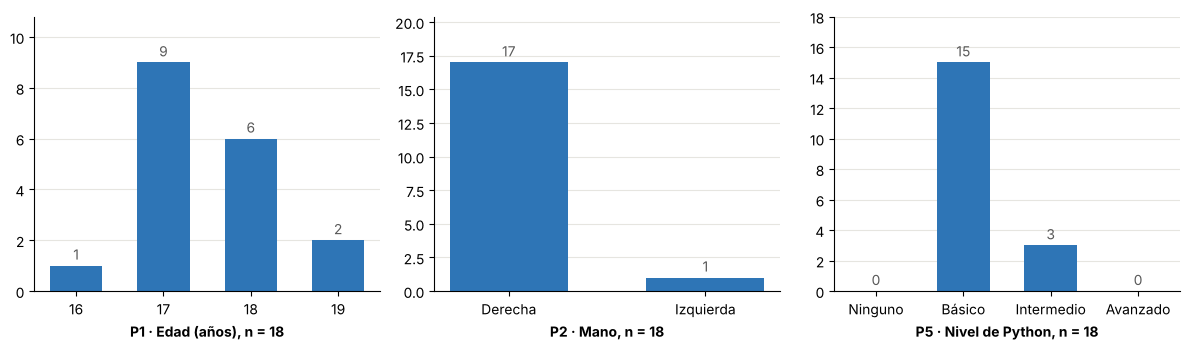

In [30]:
AZUL, NARANJA, GRIS, TINTA = "#2E75B6", "#E97132", "#BFBFBF", "#595959"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "font.size": 10})

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, t, titulo in [(axes[0], t_edad, "P1 · Edad (años), n = 18"),
                      (axes[1], t_mano, "P2 · Mano, n = 18"),
                      (axes[2], t_py,   "P5 · Nivel de Python, n = 18")]:
    b = ax.bar(t.index.astype(str), t["fi"], color=AZUL, width=0.6)
    ax.bar_label(b, padding=2, color=TINTA)
    ax.set_ylim(0, t["fi"].max() * 1.2)
    ax.set_xlabel(titulo, fontweight="bold")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Error clásico: el eje que no empieza en cero

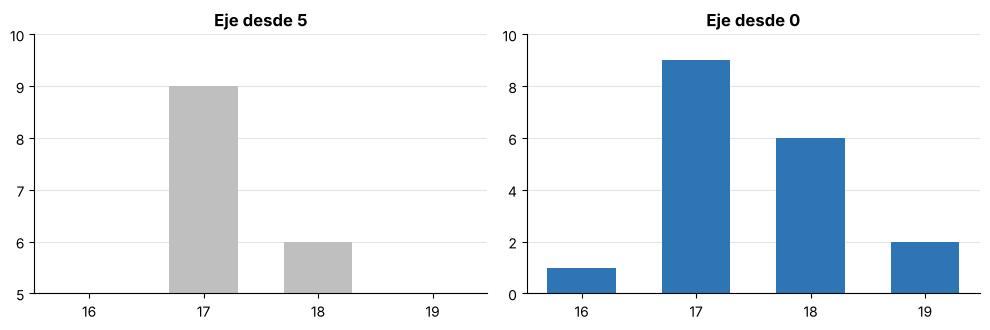

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, inicio, titulo, color in [(ax1, 5, "Eje desde 5", GRIS), (ax2, 0, "Eje desde 0", AZUL)]:
    ax.bar(t_edad.index.astype(str), t_edad["fi"], color=color, width=0.6)
    ax.set_ylim(inicio, 10)
    ax.set_title(titulo, loc="center", fontweight="bold")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

| Eje desde 5 | Eje desde 0 |
|---|---|
| 17 parece **4 veces** 18 años | En los datos es **1,5 veces** (9 / 6) |

*Fuente: Tufte, E. R. (1983). The visual display of quantitative information. Graphics Press.*

### ¿Y el gráfico circular?

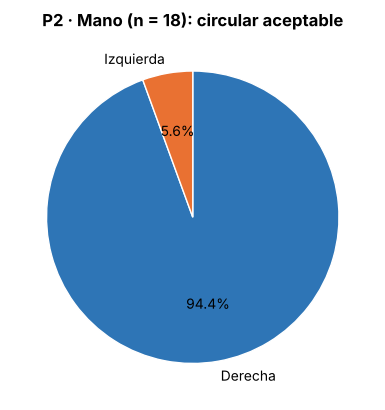

In [32]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.pie(t_mano["fi"], labels=t_mano.index.astype(str), autopct="%1.1f%%", startangle=90,
       counterclock=False, colors=[AZUL, NARANJA], wedgeprops={"edgecolor": "white"})
ax.set_title("P2 · Mano (n = 18): circular aceptable", fontweight="bold")
plt.tight_layout(); plt.show()

| | Circular | Barras |
|---|---|---|
| Muestra | Partes de un todo | Magnitud de cada categoría |
| Categorías | Pocas (2 a 4) | Cualquiera |
| Comparación | Ángulos (imprecisa) | Longitudes (precisa) |
| Ordinales | Pierde el orden | Conserva el orden |
| Aquí | P2 (mano) | P1, P5, transporte |

**Para comparar categorías, barras;** el circular solo para «qué parte del total» con pocas categorías.

### Alternativa: agrupar las categorías poco frecuentes en «Otros»

In [33]:
fi = curso["transporte"].value_counts()
principales = fi[fi >= 3]
otros = fi[fi < 3].sum()
tabla = pd.concat(
    [principales,
     pd.Series({"Otros": otros})])
tabla = tabla.to_frame("fi")
tabla["%"] = (tabla["fi"] / tabla["fi"].sum() * 100).round(1)
tabla

,fi,%
Motocicleta,8,44.4
A pie,4,22.2
Bus,3,16.7
Otros,3,16.7


**Se declara:** «Otros» reúne Bicicleta (2) y Carro particular (1), umbral fᵢ < 3. Sin esa nota, el lector no puede
reconstruir la tabla.

### Diagrama de Pareto: transporte a la universidad

In [34]:
fi = curso["transporte"].value_counts()
fi = fi[fi > 0]
pct = fi / fi.sum() * 100
# acumular antes de redondear
acum = pct.cumsum()

pareto = pd.DataFrame({"fi": fi, "%": pct.round(1), "% acum.": acum.round(1)})
pareto

,fi,%,% acum.
transporte,,,
Motocicleta,8,44.4,44.4
A pie,4,22.2,66.7
Bus,3,16.7,83.3
Bicicleta,2,11.1,94.4
Carro particular,1,5.6,100.0


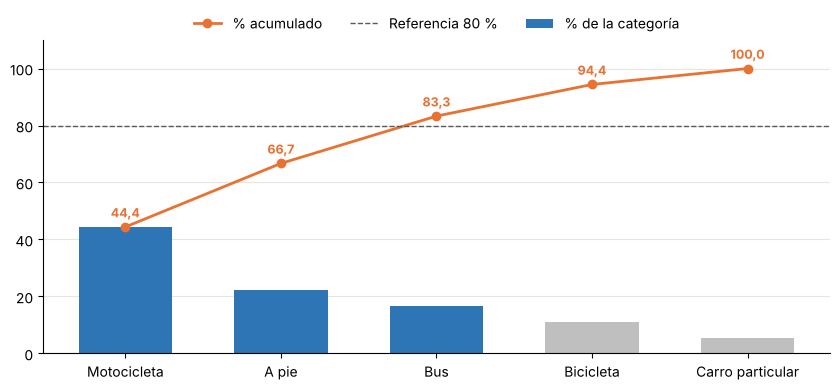

In [35]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = range(len(pareto))
ax.bar(x, pareto["%"], color=[AZUL if a <= 85 else GRIS for a in acum], width=0.6, label="% de la categoría")
ax.plot(x, pareto["% acum."], color=NARANJA, marker="o", linewidth=2, label="% acumulado")
for i, v in enumerate(pareto["% acum."]):
    ax.annotate(f"{v:.1f}".replace(".", ","), (i, v), textcoords="offset points", xytext=(0, 7),
                ha="center", color=NARANJA, fontsize=9, fontweight="bold")
ax.axhline(80, color=TINTA, linestyle="--", linewidth=1, label="Referencia 80 %")
ax.set_ylim(0, 110)
ax.set_xticks(list(x), pareto.index.astype(str))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.12))
plt.tight_layout(); plt.show()

### Leer el Pareto y decidir
| 44,4 % | 66,7 % | 83,3 % |
|---|---|---|
| Motocicleta | Moto + A pie | con Bus: 3 de 5 medios |

**Decisión de ejemplo:** si solo se puede atender un medio, es la motocicleta: casi la mitad del curso.

**El Pareto es para nominales:** en una ordinal (nivel de Python) reordenaría la escala y destruiría su significado.

## 10. P3 · Estatura por intervalos
> **P3.** Agrupen la estatura en intervalos de 0,05 m, comenzando desde 1,40 m. ¿En qué intervalo se concentra la mayor parte
> del curso? ¿Qué proporción del grupo mide menos de 1,65 m?

*Variable: estatura · cuantitativa continua*

### ¿Por qué agrupar?

In [36]:
est = curso["estatura_m"].sort_values()
print(", ".join(f"{v:.2f}" for v in est))
print("\nValores distintos:", est.nunique(), "en", n, "estudiantes")
print("Se repiten:", ", ".join(f"{v:.2f}" for v in est[est.duplicated()].unique()))
print(f"Rango: {est.max():.2f} − {est.min():.2f} = {est.max() - est.min():.2f} m")

1.44, 1.52, 1.58, 1.58, 1.60, 1.65, 1.67, 1.68, 1.72, 1.73, 1.73, 1.75, 1.75, 1.76, 1.76, 1.80, 1.82, 1.86

Valores distintos: 14 en 18 estudiantes
Se repiten: 1.58, 1.73, 1.75, 1.76
Rango: 1.86 − 1.44 = 0.42 m


**Agrupar en clases** pierde el valor exacto de cada uno y gana una tabla que se puede leer.

### Convenciones para construir las clases
| | |
|---|---|
| Límite inferior inicial | 1,40 m (dado) |
| Amplitud | 0,05 m (dada) |
| Forma de cada clase | [a, b): incluye a, excluye b |
| Número de clases | hasta cubrir el máximo: 1,86 → [1,85; 1,90) → 10 clases |
| Marca de clase | xᵢ = (a + b) / 2, el representante de la clase |

Con [a, b), el valor 1,60 va en [1,60; 1,65): ningún dato cae en dos clases.

### ¿En cuántas clases? Sturges como guía
k ≈ 1 + 3,322 · log₁₀(n)

In [37]:
k = 1 + 3.322 * np.log10(n)
print(f"n = {n} -> k ≈ {k:.2f} -> 5 o 6 clases")

n = 18 -> k ≈ 5.17 -> 5 o 6 clases


| Pocas clases (3) | Muchas clases (20) |
|---|---|
| ocultan el detalle: una sola barra para casi todo el curso | reproducen el caos original: casi una fila por estudiante |

**En P3 la decisión ya está tomada:** amplitud 0,05 desde 1,40 → 10 clases. Más detalle que Sturges, y con una clase vacía.

### `pd.cut`: dos formas de llamarlo, dos convenciones

In [38]:
# Forma 1: pandas decide los límites
pd.cut(curso["estatura_m"], bins=5).value_counts(sort=False)

estatura_m
(1.44, 1.524]     2
(1.524, 1.608]    3
(1.608, 1.692]    3
(1.692, 1.776]    7
(1.776, 1.86]     3
Name: count, dtype: int64

In [39]:
# Forma 2: límites explícitos, [a, b)
limites = np.round(
    np.arange(1.40, 1.95, 0.05), 2)
pd.cut(curso["estatura_m"],
       bins=limites, right=False).value_counts(sort=False)

estatura_m
[1.4, 1.45)    1
[1.45, 1.5)    0
[1.5, 1.55)    1
[1.55, 1.6)    2
[1.6, 1.65)    1
[1.65, 1.7)    3
[1.7, 1.75)    3
[1.75, 1.8)    4
[1.8, 1.85)    2
[1.85, 1.9)    1
Name: count, dtype: int64

In [40]:
# Mismos límites, dos convenciones de extremos
comparacion = pd.DataFrame({
    "[a, b) · right=False": pd.cut(curso["estatura_m"], bins=limites, right=False).value_counts(sort=False).values,
    "(a, b] · right=True":  pd.cut(curso["estatura_m"], bins=limites).value_counts(sort=False).values,
}, index=[f"{a:.2f} – {b:.2f}".replace(".", ",") for a, b in zip(limites[:-1], limites[1:])])
comparacion

,"[a, b) · right=False","(a, b] · right=True"
"1,40 – 1,45",1,1
"1,45 – 1,50",0,0
"1,50 – 1,55",1,1
"1,55 – 1,60",2,3
"1,60 – 1,65",1,1
"1,65 – 1,70",3,2
"1,70 – 1,75",3,5
"1,75 – 1,80",4,3
"1,80 – 1,85",2,1
"1,85 – 1,90",1,1


**Mismos 18 datos, dos convenciones, conteos distintos.** P3 usa [a, b). Si un valor coincide con un límite, la convención
decide dónde cae.

### Asignar cada estatura a su clase

In [41]:
clases = pd.cut(curso["estatura_m"], bins=limites, right=False)
asignacion = (curso.assign(clase=clases)
                   .groupby("clase", observed=False)["estatura_m"]
                   .agg(estaturas=lambda s: ", ".join(f"{v:.2f}" for v in sorted(s)) or "—",
                        fi="count"))
asignacion

,estaturas,fi
clase,,
"[1.4, 1.45)",1.44,1
"[1.45, 1.5)",—,0
"[1.5, 1.55)",1.52,1
"[1.55, 1.6)","1.58, 1.58",2
"[1.6, 1.65)",1.60,1
"[1.65, 1.7)","1.65, 1.67, 1.68",3
"[1.7, 1.75)","1.72, 1.73, 1.73",3
"[1.75, 1.8)","1.75, 1.75, 1.76, 1.76",4
"[1.8, 1.85)","1.80, 1.82",2


In [42]:
print("Suma:", " + ".join(str(v) for v in asignacion["fi"]), "=", asignacion["fi"].sum(), "= n")

Suma: 1 + 0 + 1 + 2 + 1 + 3 + 3 + 4 + 2 + 1 = 18 = n


### La tabla de P3 completa, y el código

In [43]:
limites = np.round(
    np.arange(1.40, 1.95, 0.05), 2)
clases = pd.cut(curso["estatura_m"],
                bins=limites,
                right=False)   # [a, b)
fi = clases.value_counts(sort=False)

t_est = pd.DataFrame({"Marca": [round((iv.left + iv.right) / 2, 3) for iv in fi.index],
                      "fi": fi.values}, index=fi.index)
t_est["hi"] = (t_est["fi"] / n).round(3)
t_est["Fi"] = t_est["fi"].cumsum()
t_est["Hi"] = (t_est["Fi"] / n).round(3)
t_est

,Marca,fi,hi,Fi,Hi
estatura_m,,,,,
"[1.4, 1.45)",1.425,1,0.056,1,0.056
"[1.45, 1.5)",1.475,0,0.000,1,0.056
"[1.5, 1.55)",1.525,1,0.056,2,0.111
"[1.55, 1.6)",1.575,2,0.111,4,0.222
"[1.6, 1.65)",1.625,1,0.056,5,0.278
"[1.65, 1.7)",1.675,3,0.167,8,0.444
"[1.7, 1.75)",1.725,3,0.167,11,0.611
"[1.75, 1.8)",1.775,4,0.222,15,0.833
"[1.8, 1.85)",1.825,2,0.111,17,0.944


`right=False` cierra por la izquierda: [a, b). Es la convención que usa la actividad.

In [44]:
# Respuesta P3
modal = t_est["fi"].idxmax()
F_165 = t_est.loc[pd.Interval(1.60, 1.65, closed="left"), "Fi"]
print("Clase modal:", modal, "con", t_est.loc[modal, "fi"], f"de {n} estudiantes ({t_est.loc[modal, 'fi'] / n:.1%})")
print(f"Menos de 1,65 m: F[1,60; 1,65) = {F_165} -> {F_165} / {n} = {F_165 / n:.3f} ({F_165 / n:.1%})")

Clase modal: [1.75, 1.8) con 4 de 18 estudiantes (22.2%)
Menos de 1,65 m: F[1,60; 1,65) = 5 -> 5 / 18 = 0.278 (27.8%)


**Respuesta P3**

| Clase modal | Menos de 1,65 m |
|---|---|
| **[1,75; 1,80)** · 4 de 18 estudiantes (22,2 %) | **27,8 %** · 5 de 18 |

#(estatura < 1,65) = F[1,60; 1,65) = 1 + 0 + 1 + 2 + 1 = 5 → 5 / 18 = 0,278

Se pudo leer directo porque 1,65 es un límite de clase. Con otro umbral habría que volver a los datos.

### Histograma: el gráfico de una tabla por intervalos

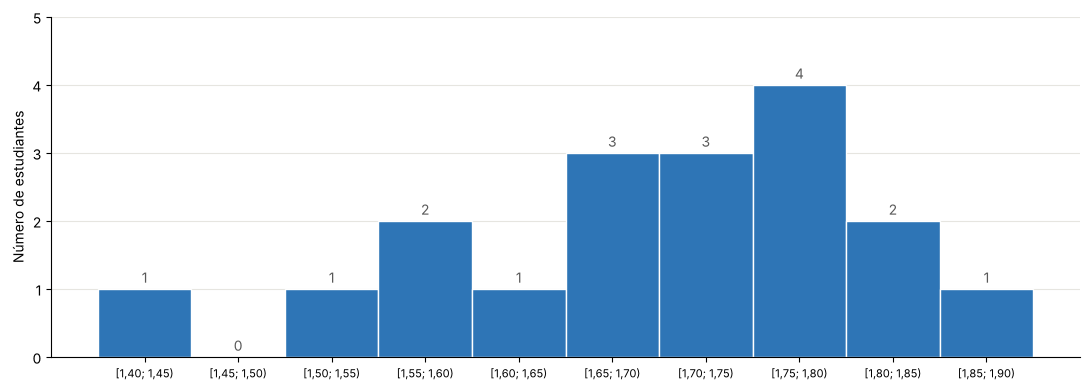

In [45]:
etq = [f"[{iv.left:.2f}; {iv.right:.2f})".replace(".", ",") for iv in t_est.index]
fig, ax = plt.subplots(figsize=(11, 4))
b = ax.bar(range(len(t_est)), t_est["fi"], width=1.0, color=AZUL, edgecolor="white")
ax.bar_label(b, padding=2, color=TINTA)
ax.set_xticks(range(len(t_est)), etq, fontsize=8)
ax.set_ylabel("Número de estudiantes"); ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

- **Barras pegadas:** las clases son contiguas.
- **Hueco en [1,45; 1,50):** fᵢ = 0, no se omite.
- **Clase modal:** la barra más alta.

### Ojiva: las acumuladas de una tabla por intervalos

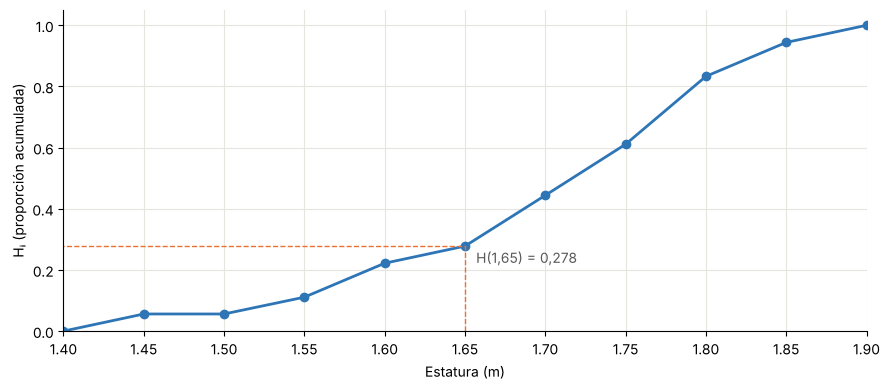

In [46]:
x_oj = limites                                   # 1.40, 1.45, ..., 1.90
H_oj = np.r_[0, t_est["Hi"].values]              # empieza en 0, termina en 1
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_oj, H_oj, color=AZUL, marker="o", linewidth=2)
ax.plot([1.65, 1.65, 1.40], [0, F_165 / n, F_165 / n], color=NARANJA, linestyle="--", linewidth=1)
ax.annotate("H(1,65) = 0,278", (1.65, F_165 / n), textcoords="offset points", xytext=(8, -12), color=TINTA)
ax.set_xticks(limites); ax.set_xlim(1.40, 1.90); ax.set_ylim(0, 1.05)
ax.set_xlabel("Estatura (m)"); ax.set_ylabel("Hᵢ (proporción acumulada)")
plt.tight_layout(); plt.show()

- **H(1,65) = 0,278:** menos de 1,65 m.
- **Empieza en (1,40; 0)** y termina en (1,90; 1).
- **Rectas:** dentro de cada clase hay valores intermedios.

## 11. P4 · Horas de estudio
> **P4.** Distribuyan las horas de estudio diario usando los intervalos [0, 1), [1, 2), [2, 3), [3, 4), [4 o más).
> ¿Cuántos estudiantes acumulan hasta 3 horas? ¿En qué intervalo se ubica exactamente la mitad del grupo?

*Variable: horas_estudio · registrada en horas enteras · se agrupa con los intervalos dados*

### La tabla de P4

In [47]:
cortes = [0, 1, 2, 3, 4, np.inf]
clases = pd.cut(
    curso["horas_estudio"],
    bins=cortes, right=False)
fi = clases.value_counts(sort=False)

etiquetas = ["[0, 1)", "[1, 2)", "[2, 3)", "[3, 4)", "[4 o más)"]
horas_que_caen = [", ".join(str(h) for h in sorted(curso.loc[clases == iv, "horas_estudio"])) or "—" for iv in fi.index]
t_h = pd.DataFrame({"Horas que caen": horas_que_caen, "fi": fi.values}, index=etiquetas)
t_h["hi"] = (t_h["fi"] / n).round(3)
t_h["Fi"] = t_h["fi"].cumsum()
t_h["Hi"] = (t_h["Fi"] / n).round(3)
t_h

,Horas que caen,fi,hi,Fi,Hi
"[0, 1)",—,0,0.000,0,0.000
"[1, 2)",1,1,0.056,1,0.056
"[2, 3)","2, 2, 2, 2",4,0.222,5,0.278
"[3, 4)","3, 3, 3, 3, 3",5,0.278,10,0.556
[4 o más),"4, 4, 4, 4, 4, 4, 4, 6",8,0.444,18,1.000


`np.inf` como último corte: la clase [4, ∞) no tiene límite superior ni marca de clase.

### «Hasta 3 horas»: una pregunta con dos lecturas

In [48]:
print("Lectura A · menos de 3 h:       F de [2, 3) =", t_h.loc["[2, 3)", "Fi"], "estudiantes")
print("Lectura B · hasta 3 h inclusive: F de [3, 4) =", t_h.loc["[3, 4)", "Fi"], "estudiantes")

Lectura A · menos de 3 h:       F de [2, 3) = 5 estudiantes
Lectura B · hasta 3 h inclusive: F de [3, 4) = 10 estudiantes


Con clases [a, b), el valor 3 pertenece a [3, 4): «hasta 3 inclusive» incluye esa clase completa.

**Regla:** cuando la pregunta es ambigua, se responde declarando la convención elegida.

### ¿En qué intervalo se ubica la mitad del grupo?

n / 2 = 9 -> primer intervalo con Fi ≥ 9: [3, 4)


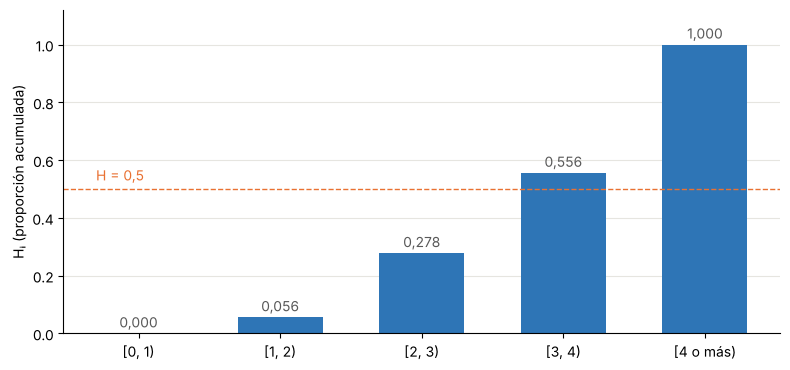

In [49]:
mitad = n / 2
intervalo_mediana = t_h.index[t_h["Fi"] >= mitad][0]
print(f"n / 2 = {mitad:.0f} -> primer intervalo con Fi ≥ {mitad:.0f}: {intervalo_mediana}")

fig, ax = plt.subplots(figsize=(8, 3.8))
b = ax.bar(t_h.index, t_h["Hi"], color=AZUL, width=0.6)
ax.bar_label(b, labels=[f"{v:.3f}".replace(".", ",") for v in t_h["Hi"]], padding=2, color=TINTA)
ax.axhline(0.5, color=NARANJA, linestyle="--", linewidth=1)
ax.text(-0.3, 0.53, "H = 0,5", color=NARANJA)
ax.set_ylim(0, 1.12); ax.set_ylabel("Hᵢ (proporción acumulada)")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

- **H = 0,5** se cruza en [3, 4).
- **F pasa de 5 a 10:** el 9.º estudiante está ahí.
- **Barras separadas, no ojiva:** el último intervalo no tiene límite superior.

**Respuesta P4**

| Distribución | Hasta 3 horas | Mitad del grupo |
|---|---|---|
| [0,1): 0 · [1,2): 1 · [2,3): 4 · [3,4): 5 · [4 o más): 8 | **5 ó 10**, según la convención declarada | **[3, 4)**: primer Fᵢ ≥ 9 |

**Intervalo de la mediana** = primer intervalo con Fᵢ ≥ n / 2

**Un intervalo abierto** no tiene marca de clase: no se puede usar para promedios, pero sí para acumular.

## 12. Tablas cruzadas
*Dos variables a la vez: combinaciones, filtros y proporciones.*

**Tabla cruzada (de contingencia):** cuenta cuántas unidades tienen cada combinación de dos variables categóricas (o agrupadas).

| | Categoría B₁ | Categoría B₂ | Total fila |
|---|---|---|---|
| Categoría A₁ | f₁₁ | f₁₂ | f₁. |
| Categoría A₂ | f₂₁ | f₂₂ | f₂. |
| Total columna | f.₁ | f.₂ | n |

**Verificación:** los márgenes son las tablas simples de cada variable, y la esquina es n.

### P6 · Mano × nivel de Python
> **P6.** De los estudiantes que escriben con la mano derecha, ¿cuántos tienen un nivel de Python intermedio o avanzado?
> Construyan una tabla cruzada mano × nivel de Python.

*Variables: mano × nivel_python*

In [50]:
tc6 = pd.crosstab(curso["mano"], curso["nivel_python"],
                  margins=True, margins_name="Total",
                  dropna=False)
tc6

nivel_python,Ninguno,Básico,Intermedio,Avanzado,Total
mano,,,,,
Derecha,0,14,3,0,17
Izquierda,0,1,0,0,1
Total,0,15,3,0,18


In [51]:
# Respuesta P6
diestros = tc6.loc["Derecha", "Total"]
int_av = tc6.loc["Derecha", "Intermedio"] + tc6.loc["Derecha", "Avanzado"]
print(f"Diestros con Intermedio o Avanzado: {int_av} de {diestros}  "
      f"({tc6.loc['Derecha', 'Intermedio']} + {tc6.loc['Derecha', 'Avanzado']})")

# Verificación: los márgenes reproducen las tablas simples de P2 y P5
print("Márgenes de fila (P2):    ", tc6["Total"].drop("Total").to_dict())
print("Márgenes de columna (P5): ", tc6.loc["Total"].drop("Total").to_dict())

Diestros con Intermedio o Avanzado: 3 de 17  (3 + 0)
Márgenes de fila (P2):     {'Derecha': 17, 'Izquierda': 1}
Márgenes de columna (P5):  {'Ninguno': 0, 'Básico': 15, 'Intermedio': 3, 'Avanzado': 0}


**Respuesta P6:** de los 17 diestros, **3** tienen nivel Intermedio o Avanzado (3 + 0).

El único zurdo es Básico. Con una sola persona en esa fila, no se puede comparar diestros con zurdos.
**Márgenes = tablas simples:** 17 y 1 (P2); 0, 15, 3, 0 (P5).

### P7 · Mascotas y transporte
> **P7.** Entre los estudiantes que tienen al menos una mascota, ¿cómo se distribuyen según el medio de transporte? ¿Hay alguna
> combinación notablemente más frecuente? ¿Qué porcentaje representa del total del grupo?

*Variables: n_mascotas (filtro ≥ 1) × transporte*

#### P7: filtrar y luego tabular

In [52]:
con_mascota = curso[curso["n_mascotas"] >= 1]
con_mascota["transporte"].value_counts()

transporte
Motocicleta         6
A pie               4
Bus                 2
Bicicleta           2
Carro particular    0
Taxi                0
Name: count, dtype: int64

In [53]:
# La tabla cruzada completa, con sin y con mascota
tc7 = pd.crosstab(curso["n_mascotas"] >= 1, curso["transporte"],
                  margins=True, margins_name="Total", dropna=False)
tc7.index = ["Sin mascota", "Con mascota", "Total"]
tc7

transporte,Bus,Motocicleta,Bicicleta,A pie,Carro particular,Taxi,Total
Sin mascota,1,2,0,0,1,0,4
Con mascota,2,6,2,4,0,0,14
Total,3,8,2,4,1,0,18


In [54]:
# Respuesta P7: el denominador cambia la respuesta
f = tc7.loc["Con mascota", "Motocicleta"]
print(f"Más frecuente: con mascota y Motocicleta: {f} estudiantes")
print(f"Sobre el total del grupo:     {f} / {n} = {f / n:.1%}   <- lo que pide P7")
print(f"Sobre quienes tienen mascota: {f} / {len(con_mascota)} = {f / len(con_mascota):.1%}   <- otra pregunta")

Más frecuente: con mascota y Motocicleta: 6 estudiantes
Sobre el total del grupo:     6 / 18 = 33.3%   <- lo que pide P7
Sobre quienes tienen mascota: 6 / 14 = 42.9%   <- otra pregunta


**Respuesta P7:** la combinación más frecuente es con mascota y Motocicleta, **6 estudiantes**.

| Sobre el total del grupo | Sobre quienes tienen mascota |
|---|---|
| **33,3 %** · 6 / 18: lo que pide P7 | 42,9 % · 6 / 14: otra pregunta |

Mismo conteo (6), dos denominadores (18 o 14), dos respuestas distintas.
**Regla:** todo porcentaje se reporta con su denominador.

### P8 · Horas de estudio × nivel de Python
> **P8.** De los estudiantes que estudian 2 horas o más al día, ¿cuántos tienen nivel intermedio o avanzado? Comparen con los que
> estudian menos de 2 horas: ¿en cuál grupo hay mayor proporción?

*Variables: horas_estudio (≥ 2 h / < 2 h) × nivel_python*

#### P8: tabla cruzada con proporciones por fila

In [55]:
curso["grupo"] = np.where(
    curso["horas_estudio"] >= 2,
    "2 h o más", "Menos de 2 h")

orden_filas = ["Menos de 2 h", "2 h o más"]
tc8 = pd.crosstab(curso["grupo"], curso["nivel_python"],
                  margins=True, margins_name="Total", dropna=False)
tc8.reindex(orden_filas + ["Total"])

nivel_python,Ninguno,Básico,Intermedio,Avanzado,Total
grupo,,,,,
Menos de 2 h,0,0,1,0,1
2 h o más,0,15,2,0,17
Total,0,15,3,0,18


In [56]:
prop = pd.crosstab(curso["grupo"],
                   curso["nivel_python"],
                   normalize="index", dropna=False).reindex(orden_filas)
prop["Int. o Av."] = prop["Intermedio"] + prop["Avanzado"]
prop.index = [f"{g} (n = {(curso['grupo'] == g).sum()})" for g in orden_filas]
(prop[["Básico", "Intermedio", "Int. o Av."]] * 100).round(1)

nivel_python,Básico,Intermedio,Int. o Av.
Menos de 2 h (n = 1),0.0,100.0,100.0
2 h o más (n = 17),88.2,11.8,11.8


**2 h o más:** 2 de 17 con nivel Intermedio = 11,8 %.

#### Respuesta P8: cuando los datos no alcanzan
| 2 h o más (n = 17) | Menos de 2 h (n = 1) |
|---|---|
| **11,8 %** · 2 Intermedio, 0 Avanzado | **100 %** · 1 persona: no es comparable |

Una proporción calculada sobre una sola persona vale 0 % o 100 %: no mide nada.

**Respuesta honesta:** los datos no alcanzan para comparar; se necesitan más estudiantes con menos de 2 h.

## Síntesis
| Pregunta | Variable | Tipo de tabla | Concepto clave |
|---|---|---|---|
| P1 | edad | datos simples, con acumuladas | moda; «18 o más» = n − F₁₇ |
| P2 | mano | datos simples, sin acumuladas | nominal; umbral del 5 % con n pequeño |
| P5 | nivel_python | datos simples, ordinal | `sort_index()` sobre category ordenada; categorías con fᵢ = 0 |
| P3 | estatura | intervalos [a, b) de amplitud dada | Sturges; `pd.cut`; marca de clase; histograma; ojiva |
| P4 | horas_estudio | intervalos dados, último abierto | convención «hasta»; intervalo de la mediana |
| P6 | mano × python | cruzada | márgenes = tablas simples |
| P7 | mascotas ≥ 1 × transporte | filtro + cruzada | declarar el denominador |
| P8 | horas ≥ 2 × python | cruzada con proporciones por fila | comparar proporciones, no conteos; cuidado con n pequeño |

**Comandos de pandas de la sesión:** `read_csv`, `head`, `shape`, `dtypes`, `nunique`, `pd.Categorical(..., categories=...,
ordered=True)`, `replace`, `isna`, `memory_usage`, `value_counts` (con `normalize=True`), `sort_index`, `sort_values`, `cumsum`,
`pd.concat`, `pd.cut` (con `bins=k`, `bins=[...]`, `right=False`), `np.where`, `pd.crosstab` (con `margins`, `normalize="index"`,
`dropna=False`).